In [ ]:
# ===== CELL 1: Setup, GPU check, dataset download, sanity check =====
import subprocess, os, sys

# 1) Install libraries (quiet)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm", "scikit-learn"], check=False)

# 2) GPU check
import torch, timm, sklearn
print("torch:", torch.__version__, "| timm:", timm.__version__, "| sklearn:", sklearn.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print("GPU memory (GB):", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1))
else:
    print("!! No GPU. Go to Runtime > Change runtime type > T4 GPU, then re-run.")

# 3) Download dataset (shallow clone, ~1.3 GB)
REPO_DIR = "/content/realwaste"
if not os.path.isdir(REPO_DIR):
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/sam-single/realwaste.git", REPO_DIR], check=True)
DATA_DIR = os.path.join(REPO_DIR, "RealWaste")

# 4) Sanity check: classes, counts, image size
from PIL import Image
classes = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)))
print("\nClasses found:", len(classes))
total = 0
for c in classes:
    n = len(os.listdir(os.path.join(DATA_DIR, c)))
    total += n
    print(f"  {c:22s} {n}")
print("Total images:", total, "(expected 4752)")

first = os.path.join(DATA_DIR, classes[0], sorted(os.listdir(os.path.join(DATA_DIR, classes[0])))[0])
im = Image.open(first)
print("Sample image size/mode:", im.size, im.mode, "(expected (524, 524) RGB)")

# 5) Folder for saving splits/results (survives only while the session lives, unless you use Drive)
os.makedirs("/content/work", exist_ok=True)
print("\nSetup done. Working folder: /content/work")

torch: 2.11.0+cu130 | timm: 1.0.30 | sklearn: 1.6.1
GPU available: True
GPU name: Tesla T4
GPU memory (GB): 15.6

Classes found: 9
  Cardboard              461
  Food Organics          411
  Glass                  420
  Metal                  790
  Miscellaneous Trash    495
  Paper                  500
  Plastic                921
  Textile Trash          318
  Vegetation             436
Total images: 4752 (expected 4752)
Sample image size/mode: (524, 524) RGB (expected (524, 524) RGB)

Setup done. Working folder: /content/work


In [ ]:
# ===== CELL 2: Create & save stratified train/val/test split =====
import os, numpy as np, pandas as pd
from sklearn.model_selection import train_test_split

SEED = 42
DATA_DIR = "/content/realwaste/RealWaste"
WORK = "/content/work"

# 1) Build dataframe of all images
rows = []
for c in sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d))):
    for f in sorted(os.listdir(os.path.join(DATA_DIR, c))):
        rows.append((os.path.join(c, f), c))          # relative path + label name
df = pd.DataFrame(rows, columns=["path", "label"])
classes = sorted(df["label"].unique())
class_to_idx = {c: i for i, c in enumerate(classes)}
df["y"] = df["label"].map(class_to_idx)

# 2) Near-duplicate images found earlier -> force into TRAIN only (avoid leakage across splits)
force_train_files = {
    "Food Organics/Food Organics_81.jpg", "Food Organics/Food Organics_82.jpg",
    "Glass/Glass_170.jpg", "Paper/Paper_140.jpg",
}
is_forced = df["path"].str.replace("\\", "/", regex=False).isin(force_train_files)
forced = df[is_forced].copy()
pool = df[~is_forced].copy()
print("Forced into train (near-duplicates):", len(forced))

# 3) Stratified 70/15/15 split on the rest
train_pool, temp = train_test_split(pool, test_size=0.30, stratify=pool["y"], random_state=SEED)
val, test = train_test_split(temp, test_size=0.50, stratify=temp["y"], random_state=SEED)
train = pd.concat([train_pool, forced]).sample(frac=1.0, random_state=SEED).reset_index(drop=True)
val = val.reset_index(drop=True); test = test.reset_index(drop=True)

# 4) Safety checks: no overlap between splits
s_tr, s_va, s_te = set(train["path"]), set(val["path"]), set(test["path"])
assert not (s_tr & s_va) and not (s_tr & s_te) and not (s_va & s_te), "Leak: overlap between splits!"
assert len(train) + len(val) + len(test) == len(df)
print("No overlap between splits: OK")

# 5) Save CSVs
train.to_csv(f"{WORK}/train.csv", index=False)
val.to_csv(f"{WORK}/val.csv", index=False)
test.to_csv(f"{WORK}/test.csv", index=False)
pd.Series(class_to_idx).to_json(f"{WORK}/class_to_idx.json")

# 6) Report
print(f"\nSizes -> train: {len(train)} | val: {len(val)} | test: {len(test)}")
summary = pd.DataFrame({
    "train": train["label"].value_counts(),
    "val": val["label"].value_counts(),
    "test": test["label"].value_counts(),
}).loc[classes]
print(summary.to_string())

# 7) Class weights (inverse frequency, normalised to mean 1) for the imbalance experiment
counts = train["y"].value_counts().sort_index().values
class_weights = counts.sum() / (len(counts) * counts)
print("\nClass weights (train):")
for c, w in zip(classes, class_weights):
    print(f"  {c:22s} {w:.3f}")
np.save(f"{WORK}/class_weights.npy", class_weights)

Forced into train (near-duplicates): 4
No overlap between splits: OK

Sizes -> train: 3327 | val: 712 | test: 713
                     train  val  test
label                                
Cardboard              323   69    69
Food Organics          288   62    61
Glass                  294   63    63
Metal                  553  118   119
Miscellaneous Trash    346   74    75
Paper                  350   75    75
Plastic                645  138   138
Textile Trash          223   48    47
Vegetation             305   65    66

Class weights (train):
  Cardboard              1.144
  Food Organics          1.284
  Glass                  1.257
  Metal                  0.668
  Miscellaneous Trash    1.068
  Paper                  1.056
  Plastic                0.573
  Textile Trash          1.658
  Vegetation             1.212


Cache ready in 29s | train (3327, 224, 224, 3) val (712, 224, 224, 3) test (713, 224, 224, 3) | RAM ~715 MB

Batch: (32, 3, 224, 224) torch.float32 | labels: [1, 2, 6, 5, 5, 6, 1, 1, 2, 8]
Normalized batch mean 0.572 std 0.816 (should be roughly 0 and 1)
Loader speed: 156 images/sec (30 batches in 6.2s)


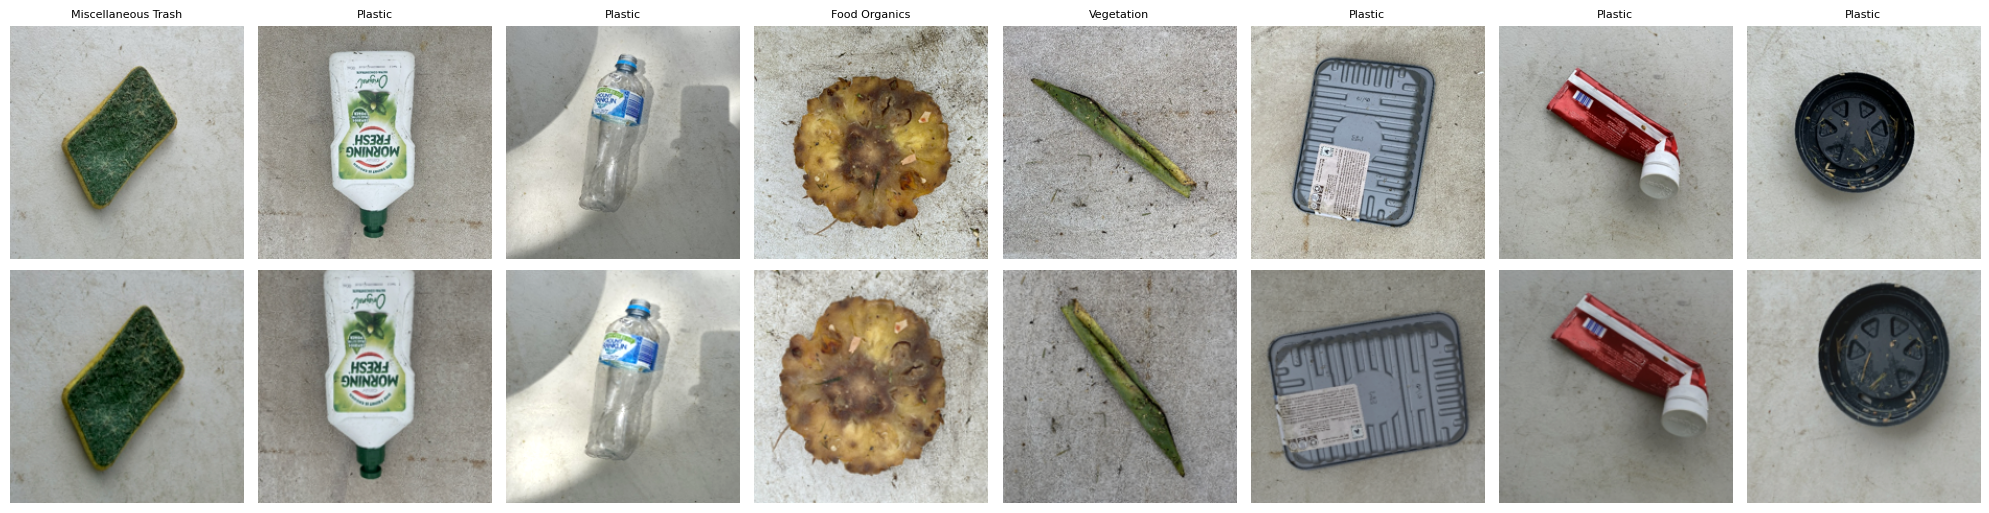

In [ ]:
# ===== CELL 3: Cache images in RAM + augmentation pipeline + DataLoaders =====
import os, time, json, random
import numpy as np, pandas as pd, torch
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from torchvision.transforms import v2
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

SEED = 42
IMG_SIZE = 224          # start here; we can try 384 later by changing this one number
BATCH_SIZE = 32
DATA_DIR = "/content/realwaste/RealWaste"
WORK = "/content/work"

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()

train_df = pd.read_csv(f"{WORK}/train.csv"); val_df = pd.read_csv(f"{WORK}/val.csv"); test_df = pd.read_csv(f"{WORK}/test.csv")
class_to_idx = json.load(open(f"{WORK}/class_to_idx.json"))
classes = sorted(class_to_idx, key=class_to_idx.get)

# ---- 1) Load + resize every image once (whole image, no cropping) and cache as uint8 ----
def load_resize(rel_path):
    im = Image.open(os.path.join(DATA_DIR, rel_path)).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BICUBIC)
    return np.asarray(im, dtype=np.uint8)

def build_cache(df, name):
    cache_file = f"{WORK}/cache_{name}_{IMG_SIZE}.npy"
    if os.path.exists(cache_file):
        return np.load(cache_file)
    with ThreadPoolExecutor(8) as ex:
        arr = np.stack(list(ex.map(load_resize, df["path"].tolist())))
    np.save(cache_file, arr)
    return arr

t0 = time.time()
X_train = build_cache(train_df, "train"); X_val = build_cache(val_df, "val"); X_test = build_cache(test_df, "test")
print(f"Cache ready in {time.time()-t0:.0f}s | train {X_train.shape} val {X_val.shape} test {X_test.shape} | "
      f"RAM ~{(X_train.nbytes+X_val.nbytes+X_test.nbytes)/1e6:.0f} MB")

# ---- 2) Augmentation (train only) ----
class RandRot90:
    def __call__(self, x):
        return torch.rot90(x, random.randint(0, 3), dims=(1, 2))

MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]   # ImageNet stats (pretrained weights)
train_tf = v2.Compose([
    RandRot90(),
    v2.RandomHorizontalFlip(0.5),
    v2.RandomVerticalFlip(0.5),
    v2.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(0.9, 1.1), antialias=True),
    v2.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.02),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(MEAN, STD),
])
eval_tf = v2.Compose([v2.ToDtype(torch.float32, scale=True), v2.Normalize(MEAN, STD)])

class ArrDataset(Dataset):
    def __init__(self, X, y, tf):
        self.X = torch.from_numpy(X).permute(0, 3, 1, 2).contiguous()   # N,3,H,W uint8
        self.y = torch.tensor(y, dtype=torch.long); self.tf = tf
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.tf(self.X[i]), self.y[i]

train_ds = ArrDataset(X_train, train_df["y"].values, train_tf)
val_ds   = ArrDataset(X_val,   val_df["y"].values,   eval_tf)
test_ds  = ArrDataset(X_test,  test_df["y"].values,  eval_tf)

def make_loaders(batch_size=BATCH_SIZE, workers=2):
    g = torch.Generator(); g.manual_seed(SEED)
    tl = DataLoader(train_ds, batch_size=batch_size, shuffle=True, num_workers=workers, pin_memory=True, drop_last=True, generator=g, persistent_workers=True)
    vl = DataLoader(val_ds, batch_size=batch_size*2, shuffle=False, num_workers=workers, pin_memory=True)
    te = DataLoader(test_ds, batch_size=batch_size*2, shuffle=False, num_workers=workers, pin_memory=True)
    return tl, vl, te
train_loader, val_loader, test_loader = make_loaders()

# ---- 3) Checks: one batch + loader speed ----
xb, yb = next(iter(train_loader))
print("\nBatch:", tuple(xb.shape), xb.dtype, "| labels:", yb.tolist()[:10])
print(f"Normalized batch mean {xb.mean():.3f} std {xb.std():.3f} (should be roughly 0 and 1)")
t0 = time.time(); n = 0
for i, (xb, yb) in enumerate(train_loader):
    n += len(yb)
    if i == 29: break
dt = time.time() - t0
print(f"Loader speed: {n/dt:.0f} images/sec (30 batches in {dt:.1f}s)")

# ---- 4) Augmentation preview (top: original, bottom: augmented) ----
def denorm(t):
    m = torch.tensor(MEAN).view(3,1,1); s = torch.tensor(STD).view(3,1,1)
    return (t*s+m).clamp(0,1).permute(1,2,0).numpy()
idxs = list(range(8))
fig, ax = plt.subplots(2, 8, figsize=(20, 5.3))
for k, i in enumerate(idxs):
    ax[0,k].imshow(X_train[i]); ax[0,k].set_title(classes[train_df['y'][i]], fontsize=8); ax[0,k].axis("off")
    ax[1,k].imshow(denorm(train_ds[i][0])); ax[1,k].axis("off")
plt.tight_layout(); plt.savefig(f"{WORK}/aug_preview.png", dpi=80); plt.show()

In [ ]:
# ===== CELL 4: Training engine + first run (EfficientNet-B0 pipeline check) =====
import time, json, math
import numpy as np, torch, torch.nn as nn, timm
from sklearn.metrics import f1_score, accuracy_score, classification_report

device = "cuda"
torch.backends.cudnn.benchmark = True
val_criterion = nn.CrossEntropyLoss()

@torch.no_grad()
def evaluate(model, loader):
    model.eval(); logits_all, y_all = [], []; tot = 0.0
    for xb, yb in loader:
        xb = xb.to(device, non_blocking=True).to(memory_format=torch.channels_last); yb = yb.to(device, non_blocking=True)
        with torch.autocast("cuda", dtype=torch.float16):
            out = model(xb)
        tot += val_criterion(out.float(), yb).item() * len(yb)
        logits_all.append(out.float().cpu()); y_all.append(yb.cpu())
    logits = torch.cat(logits_all); y = torch.cat(y_all).numpy(); pred = logits.argmax(1).numpy()
    return {"loss": tot/len(y), "acc": accuracy_score(y, pred), "f1": f1_score(y, pred, average="macro"),
            "logits": logits, "y": y, "pred": pred}

def run_experiment(arch, tag, head_epochs=3, ft_epochs=25, patience=7, lr_head=1e-3, lr_backbone=1e-4,
                   weight_decay=0.01, label_smoothing=0.0, use_class_weights=False, drop_rate=0.2):
    seed_everything(SEED)
    model = timm.create_model(arch, pretrained=True, num_classes=len(classes), drop_rate=drop_rate)
    model = model.to(device).to(memory_format=torch.channels_last)
    n_params = sum(p.numel() for p in model.parameters()) / 1e6
    print(f"[{tag}] {arch} | {n_params:.1f}M params | class_weights={use_class_weights} | label_smoothing={label_smoothing}")

    cw = torch.tensor(np.load(f"{WORK}/class_weights.npy"), dtype=torch.float32, device=device) if use_class_weights else None
    criterion = nn.CrossEntropyLoss(weight=cw, label_smoothing=label_smoothing)
    scaler = torch.amp.GradScaler("cuda")
    head_params = list(model.get_classifier().parameters())
    head_ids = {id(p) for p in head_params}
    backbone_params = [p for p in model.parameters() if id(p) not in head_ids]

    def train_epoch(opt, sched=None):
        model.train(); tl, n, t0 = 0.0, 0, time.time()
        for xb, yb in train_loader:
            xb = xb.to(device, non_blocking=True).to(memory_format=torch.channels_last); yb = yb.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16):
                out = model(xb)
            loss = criterion(out.float(), yb)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            if sched: sched.step()
            tl += loss.item() * len(yb); n += len(yb)
        return tl / n, n / (time.time() - t0)

    history, best_f1, best_ep, bad = [], -1.0, 0, 0
    ckpt = f"{WORK}/ckpt_{tag}.pt"

    def log(ep, stage, trl, ips, v):
        history.append({"epoch": ep, "stage": stage, "train_loss": trl, "val_loss": v["loss"], "val_acc": v["acc"], "val_f1": v["f1"]})
        print(f"ep {ep:02d} [{stage:4s}] train_loss {trl:.3f} | val_loss {v['loss']:.3f} acc {v['acc']:.4f} f1 {v['f1']:.4f} | {ips:.0f} img/s")

    # ---- Stage 1: train only the new classifier head ----
    for p in backbone_params: p.requires_grad = False
    opt = torch.optim.AdamW(head_params, lr=lr_head, weight_decay=weight_decay)
    for ep in range(1, head_epochs + 1):
        trl, ips = train_epoch(opt); v = evaluate(model, val_loader); log(ep, "head", trl, ips, v)

    # ---- Stage 2: fine-tune everything (warmup 1 epoch + cosine decay) ----
    for p in backbone_params: p.requires_grad = True
    opt = torch.optim.AdamW([{"params": backbone_params, "lr": lr_backbone}, {"params": head_params, "lr": lr_head}], weight_decay=weight_decay)
    total, warm = ft_epochs * len(train_loader), len(train_loader)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else max(0.01, 0.5 * (1 + math.cos(math.pi * (s - warm) / (total - warm)))))
    for ep in range(head_epochs + 1, head_epochs + ft_epochs + 1):
        trl, ips = train_epoch(opt, sched); v = evaluate(model, val_loader); log(ep, "full", trl, ips, v)
        if v["f1"] > best_f1:
            best_f1, best_ep, bad = v["f1"], ep, 0; torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
            if bad >= patience: print(f"Early stop at epoch {ep} (best epoch {best_ep}, val F1 {best_f1:.4f})"); break

    # ---- Reload best weights, final validation report ----
    model.load_state_dict(torch.load(ckpt)); v = evaluate(model, val_loader)
    print(f"\nBEST epoch {best_ep} | val acc {v['acc']:.4f} | val macro-F1 {v['f1']:.4f} | val loss {v['loss']:.3f}")
    print(classification_report(v["y"], v["pred"], target_names=classes, digits=3))
    res = {"tag": tag, "arch": arch, "params_M": n_params, "best_epoch": best_ep, "val_acc": v["acc"], "val_f1": v["f1"],
           "img_size": IMG_SIZE, "class_weights": use_class_weights, "label_smoothing": label_smoothing, "history": history}
    json.dump(res, open(f"{WORK}/results_{tag}.json", "w"))
    return model, res

model, res = run_experiment("efficientnet_b0", "effb0_224_base")

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

[effb0_224_base] efficientnet_b0 | 4.0M params | class_weights=False | label_smoothing=0.0
ep 01 [head] train_loss 3.279 | val_loss 2.471 acc 0.3329 f1 0.3146 | 108 img/s
ep 02 [head] train_loss 2.230 | val_loss 1.890 acc 0.4480 f1 0.4291 | 142 img/s
ep 03 [head] train_loss 1.778 | val_loss 1.526 acc 0.5309 f1 0.5232 | 153 img/s


/tmp/ipykernel_4746/4288594090.py:47: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if sched: sched.step()


ep 04 [full] train_loss 1.469 | val_loss 1.018 acc 0.6742 f1 0.6751 | 77 img/s
ep 05 [full] train_loss 0.840 | val_loss 0.734 acc 0.7640 f1 0.7629 | 136 img/s
ep 06 [full] train_loss 0.571 | val_loss 0.513 acc 0.8230 f1 0.8305 | 134 img/s
ep 07 [full] train_loss 0.422 | val_loss 0.475 acc 0.8469 f1 0.8523 | 135 img/s
ep 08 [full] train_loss 0.313 | val_loss 0.427 acc 0.8567 f1 0.8574 | 132 img/s
ep 09 [full] train_loss 0.252 | val_loss 0.420 acc 0.8694 f1 0.8707 | 95 img/s
ep 10 [full] train_loss 0.214 | val_loss 0.348 acc 0.8933 f1 0.8962 | 134 img/s
ep 11 [full] train_loss 0.175 | val_loss 0.354 acc 0.8820 f1 0.8861 | 128 img/s
ep 12 [full] train_loss 0.142 | val_loss 0.356 acc 0.8862 f1 0.8894 | 134 img/s
ep 13 [full] train_loss 0.120 | val_loss 0.334 acc 0.8989 f1 0.9005 | 134 img/s
ep 14 [full] train_loss 0.101 | val_loss 0.329 acc 0.8961 f1 0.8990 | 135 img/s
ep 15 [full] train_loss 0.102 | val_loss 0.343 acc 0.8933 f1 0.8962 | 134 img/s
ep 16 [full] train_loss 0.085 | val_loss 0

GPU memory used by data: 767 MB


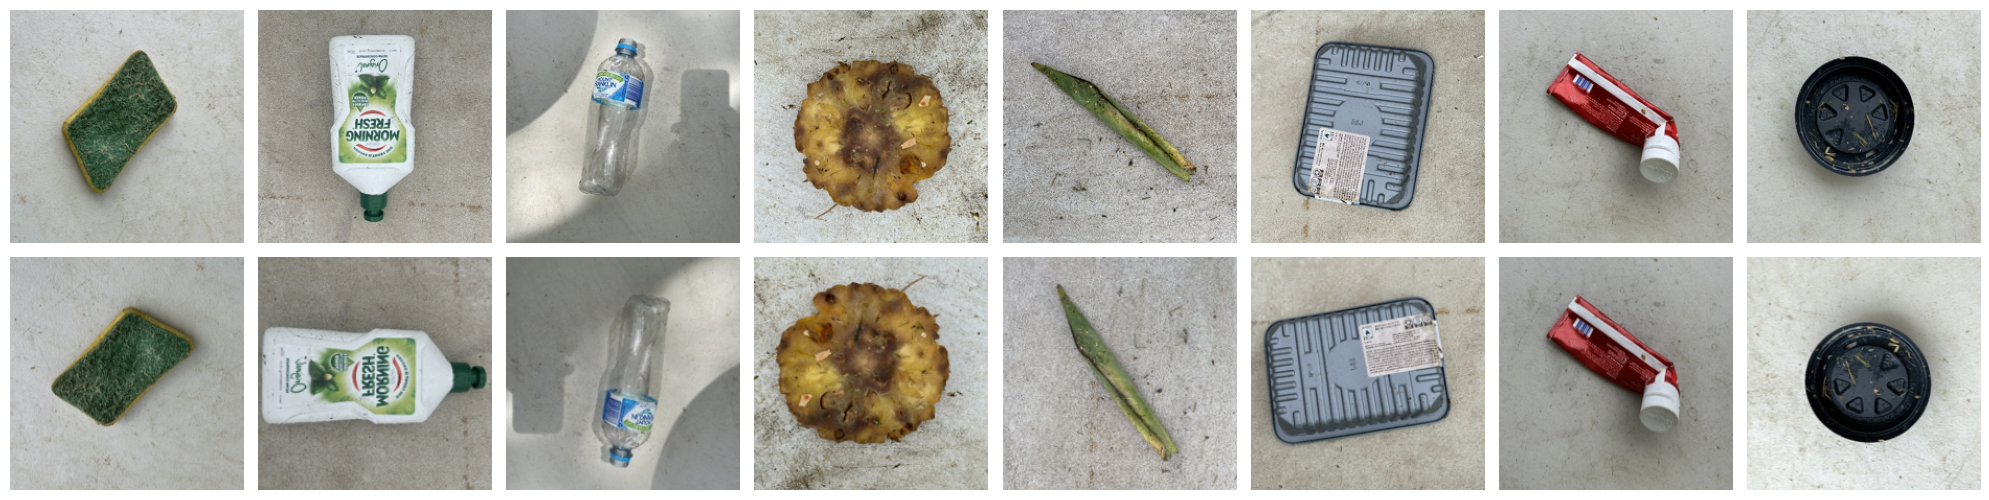

Loader alone: 4537 images/sec
[effb0_224_gpuaug] efficientnet_b0 | 4.0M params | class_weights=False | label_smoothing=0.0
ep 01 [head] train_loss 3.218 | val_loss 2.445 acc 0.3427 f1 0.3285 | 1285 img/s
ep 02 [head] train_loss 2.224 | val_loss 1.837 acc 0.4705 f1 0.4541 | 1273 img/s
ep 03 [head] train_loss 1.785 | val_loss 1.528 acc 0.5365 f1 0.5375 | 1279 img/s


/tmp/ipykernel_4746/4288594090.py:47: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if sched: sched.step()


ep 04 [full] train_loss 1.440 | val_loss 1.047 acc 0.6699 f1 0.6665 | 442 img/s
ep 05 [full] train_loss 0.865 | val_loss 0.659 acc 0.7823 f1 0.7847 | 438 img/s
ep 06 [full] train_loss 0.564 | val_loss 0.553 acc 0.8301 f1 0.8350 | 437 img/s
ep 07 [full] train_loss 0.412 | val_loss 0.445 acc 0.8581 f1 0.8660 | 433 img/s
ep 08 [full] train_loss 0.311 | val_loss 0.405 acc 0.8764 f1 0.8802 | 430 img/s
ep 09 [full] train_loss 0.233 | val_loss 0.378 acc 0.8834 f1 0.8850 | 427 img/s
ep 10 [full] train_loss 0.202 | val_loss 0.378 acc 0.8834 f1 0.8829 | 425 img/s
ep 11 [full] train_loss 0.150 | val_loss 0.355 acc 0.8876 f1 0.8887 | 423 img/s
ep 12 [full] train_loss 0.154 | val_loss 0.328 acc 0.8933 f1 0.8961 | 419 img/s
ep 13 [full] train_loss 0.110 | val_loss 0.323 acc 0.9031 f1 0.9032 | 415 img/s
ep 14 [full] train_loss 0.095 | val_loss 0.308 acc 0.9045 f1 0.9059 | 414 img/s
ep 15 [full] train_loss 0.090 | val_loss 0.341 acc 0.8919 f1 0.8911 | 413 img/s
ep 16 [full] train_loss 0.084 | val_loss

In [ ]:
# ===== CELL 5: GPU-side data loading + augmentation, then re-run EfficientNet-B0 =====
import gc, math, time
import numpy as np, torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

class GPULoader:
    def __init__(self, X, y, batch_size, train, seed=SEED):
        self.X = torch.from_numpy(X).permute(0, 3, 1, 2).contiguous().to(device)      # uint8, lives on GPU
        self.y = torch.from_numpy(np.asarray(y)).long().to(device)
        self.bs, self.train = batch_size, train
        self.mean = torch.tensor(MEAN, device=device).view(1, 3, 1, 1)
        self.std = torch.tensor(STD, device=device).view(1, 3, 1, 1)
        self.g = torch.Generator(device=device); self.g.manual_seed(seed)
        self.cos_t = torch.tensor([1., 0., -1., 0.], device=device)
        self.sin_t = torch.tensor([0., 1., 0., -1.], device=device)

    def __len__(self):
        n = len(self.y)
        return n // self.bs if self.train else math.ceil(n / self.bs)

    def _u(self, n, lo=0.0, hi=1.0):
        return lo + (hi - lo) * torch.rand(n, device=device, generator=self.g)

    def _augment(self, x):                                   # x: B,3,H,W float in [0,1]
        B = x.shape[0]
        k = torch.randint(0, 4, (B,), device=device, generator=self.g)
        cos, sin = self.cos_t[k], self.sin_t[k]               # random 90-degree rotation
        s = self._u(B, 0.7, 1.0).sqrt(); ar = self._u(B, 0.9, 1.1).sqrt()
        sx, sy = (s * ar).clamp(max=1.0), (s / ar).clamp(max=1.0)   # random crop size (area 70-100%)
        fx = (self._u(B) < 0.5).float() * 2 - 1; fy = (self._u(B) < 0.5).float() * 2 - 1   # flips
        a, b = fx * sx, fy * sy
        ex = cos.abs() * sx + sin.abs() * sy; ey = sin.abs() * sx + cos.abs() * sy
        tx = self._u(B, -1, 1) * (1 - ex); ty = self._u(B, -1, 1) * (1 - ey)               # crop position
        theta = torch.stack([torch.stack([cos * a, -sin * b, tx], 1),
                             torch.stack([sin * a,  cos * b, ty], 1)], 1)                   # B,2,3
        grid = F.affine_grid(theta, list(x.shape), align_corners=False)
        x = F.grid_sample(x, grid, mode="bilinear", padding_mode="reflection", align_corners=False)
        # colour: brightness, contrast, saturation (per-sample random factors)
        x = x * self._u(B, 0.8, 1.2).view(B, 1, 1, 1)
        gray = (0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3])
        m = gray.mean(dim=(1, 2, 3), keepdim=True)
        x = (x - m) * self._u(B, 0.8, 1.2).view(B, 1, 1, 1) + m
        gray = (0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3])
        x = gray + (x - gray) * self._u(B, 0.9, 1.1).view(B, 1, 1, 1)
        return x.clamp(0, 1)

    def __iter__(self):
        n = len(self.y)
        idx = torch.randperm(n, device=device, generator=self.g) if self.train else torch.arange(n, device=device)
        for i in range(len(self)):
            b = idx[i * self.bs:(i + 1) * self.bs]
            x = self.X[b].float().div_(255)
            if self.train: x = self._augment(x)
            x = ((x - self.mean) / self.std).contiguous(memory_format=torch.channels_last)
            yield x, self.y[b]

# free the old CPU loaders, build GPU ones
del train_loader, val_loader, test_loader; gc.collect()
train_loader = GPULoader(X_train, train_df["y"].values, BATCH_SIZE, True)
val_loader   = GPULoader(X_val,   val_df["y"].values,   64, False)
test_loader  = GPULoader(X_test,  test_df["y"].values,  64, False)
print(f"GPU memory used by data: {torch.cuda.memory_allocated()/1e6:.0f} MB")

# preview: top = original, bottom = GPU-augmented
xb = train_loader.X[:8].float() / 255
aug = train_loader._augment(xb)
fig, ax = plt.subplots(2, 8, figsize=(20, 5.3))
for k in range(8):
    ax[0, k].imshow(xb[k].permute(1, 2, 0).cpu().numpy()); ax[0, k].axis("off")
    ax[1, k].imshow(aug[k].permute(1, 2, 0).cpu().numpy()); ax[1, k].axis("off")
plt.tight_layout(); plt.savefig(f"{WORK}/aug_preview_gpu.png", dpi=80); plt.show()

# speed test of the loader alone
torch.cuda.synchronize(); t0 = time.time(); n = 0
for i, (xb, yb) in enumerate(train_loader):
    n += len(yb)
    if i == 49: break
torch.cuda.synchronize(); print(f"Loader alone: {n/(time.time()-t0):.0f} images/sec")

# same recipe as Cell 4, for a like-for-like comparison
train_loader.g.manual_seed(SEED)
model, res = run_experiment("efficientnet_b0", "effb0_224_gpuaug")

In [ ]:
# ===== CELL 6: Top confusions for EfficientNet-B0, then model sweep (part 1) =====
import io, contextlib, glob, json, time, os
import numpy as np, pandas as pd, torch
from sklearn.metrics import confusion_matrix, recall_score

# ---- A) Which classes get confused? (EfficientNet-B0 from Cell 5, validation set) ----
v = evaluate(model, val_loader)
cm = confusion_matrix(v["y"], v["pred"])
pairs = [(cm[i, j], classes[i], classes[j]) for i in range(len(classes)) for j in range(len(classes)) if i != j and cm[i, j] > 0]
print("Top confusions (true -> predicted : count):")
for cnt, t, p in sorted(pairs, reverse=True)[:8]:
    print(f"  {t:20s} -> {p:20s} : {cnt}")
del model; torch.cuda.empty_cache()

# ---- B) Sweep ----
MODELS = ["mobilenetv2_100", "resnet50", "densenet121"]     # part 1 (we edit this list for later parts)

@torch.no_grad()
def infer_speed(m, loader, reps=3):
    m.eval(); torch.cuda.synchronize(); t0 = time.time(); n = 0
    for _ in range(reps):
        for xb, yb in loader:
            with torch.autocast("cuda", dtype=torch.float16): m(xb)
            n += len(yb)
    torch.cuda.synchronize(); return n / (time.time() - t0)

for arch in MODELS:
    tag = f"{arch}_224"
    if os.path.exists(f"{WORK}/results_{tag}.json"):
        print(f"[skip] {tag} already done"); continue
    train_loader.g.manual_seed(SEED)
    t0 = time.time(); buf = io.StringIO()
    try:
        with contextlib.redirect_stdout(buf):
            m, r = run_experiment(arch, tag)
    except Exception:
        print("FAILED:", tag); print(buf.getvalue()[-1500:]); raise
    mins = (time.time() - t0) / 60
    v = evaluate(m, val_loader)
    rec = recall_score(v["y"], v["pred"], average=None)
    r.update({"train_minutes": mins, "infer_img_s": infer_speed(m, val_loader), "val_recall": dict(zip(classes, rec.tolist()))})
    json.dump(r, open(f"{WORK}/results_{tag}.json", "w"))
    last_ep = r["history"][-1]["epoch"]
    print(f"{tag:22s} params {r['params_M']:5.1f}M | best ep {r['best_epoch']:2d}/{last_ep} | val acc {r['val_acc']:.4f} F1 {r['val_f1']:.4f} | {mins:.1f} min | infer {r['infer_img_s']:.0f} img/s")
    print("   recall:", {k[:8]: round(x, 2) for k, x in r["val_recall"].items()})
    del m; torch.cuda.empty_cache()

# ---- C) Running comparison table (all saved runs) ----
rows = []
for f in sorted(glob.glob(f"{WORK}/results_*.json")):
    r = json.load(open(f))
    rows.append({"run": r["tag"], "params_M": round(r["params_M"], 1), "best_ep": r["best_epoch"],
                 "val_acc": round(r["val_acc"], 4), "val_f1": round(r["val_f1"], 4)})
print("\n", pd.DataFrame(rows).sort_values("val_f1", ascending=False).to_string(index=False))

Top confusions (true -> predicted : count):
  Plastic              -> Metal                : 11
  Paper                -> Cardboard            : 5
  Miscellaneous Trash  -> Textile Trash        : 4
  Food Organics        -> Vegetation           : 4
  Plastic              -> Glass                : 3
  Plastic              -> Cardboard            : 3
  Miscellaneous Trash  -> Plastic              : 3
  Metal                -> Plastic              : 3


model.safetensors: reconstructing file:   0%|          |  0.00B / 14.2MB            

model.safetensors: downloading bytes:           |  0.00B            

/tmp/ipykernel_4746/4288594090.py:47: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if sched: sched.step()


mobilenetv2_100_224    params   2.2M | best ep 21/28 | val acc 0.8792 F1 0.8818 | 2.9 min | infer 1968 img/s
   recall: {'Cardboar': 0.91, 'Food Org': 0.87, 'Glass': 0.89, 'Metal': 0.87, 'Miscella': 0.76, 'Paper': 0.92, 'Plastic': 0.87, 'Textile ': 0.9, 'Vegetati': 0.95}


model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 32.3MB            

model.safetensors: downloading bytes:           |  0.00B            

/tmp/ipykernel_4746/4288594090.py:47: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if sched: sched.step()


densenet121_224        params   7.0M | best ep 14/21 | val acc 0.9213 F1 0.9205 | 5.2 min | infer 603 img/s
   recall: {'Cardboar': 0.97, 'Food Org': 0.87, 'Glass': 0.95, 'Metal': 0.93, 'Miscella': 0.81, 'Paper': 0.92, 'Plastic': 0.93, 'Textile ': 0.9, 'Vegetati': 0.98}

                 run  params_M  best_ep  val_acc  val_f1
       resnet50_224      23.5       26   0.9213  0.9224
    densenet121_224       7.0       14   0.9213  0.9205
   effb0_224_gpuaug       4.0       28   0.9143  0.9171
     effb0_224_base       4.0       23   0.9129  0.9167
mobilenetv2_100_224       2.2       21   0.8792  0.8818


In [ ]:
# ===== CELL 7: Reusable sweep + part 2 (stronger backbones) =====
def sweep(models, suffix="224", **kw):
    """Train each arch with the standard recipe (extra kwargs go to run_experiment, e.g. use_class_weights=True)."""
    for arch in models:
        tag = f"{arch}_{suffix}"
        if os.path.exists(f"{WORK}/results_{tag}.json"):
            print(f"[skip] {tag} already done"); continue
        train_loader.g.manual_seed(SEED)
        t0 = time.time(); buf = io.StringIO()
        try:
            with contextlib.redirect_stdout(buf):
                m, r = run_experiment(arch, tag, **kw)
        except Exception:
            print("FAILED:", tag); print(buf.getvalue()[-1500:]); raise
        mins = (time.time() - t0) / 60
        v = evaluate(m, val_loader)
        rec = recall_score(v["y"], v["pred"], average=None)
        r.update({"train_minutes": mins, "infer_img_s": infer_speed(m, val_loader), "val_recall": dict(zip(classes, rec.tolist()))})
        json.dump(r, open(f"{WORK}/results_{tag}.json", "w"))
        last_ep = r["history"][-1]["epoch"]
        print(f"{tag:26s} params {r['params_M']:5.1f}M | best ep {r['best_epoch']:2d}/{last_ep} | val acc {r['val_acc']:.4f} F1 {r['val_f1']:.4f} | {mins:.1f} min | infer {r['infer_img_s']:.0f} img/s")
        print("   recall:", {k[:8]: round(x, 2) for k, x in r["val_recall"].items()})
        del m; torch.cuda.empty_cache()

def show_table():
    rows = []
    for f in sorted(glob.glob(f"{WORK}/results_*.json")):
        r = json.load(open(f))
        rows.append({"run": r["tag"], "params_M": round(r["params_M"], 1), "best_ep": r["best_epoch"],
                     "val_acc": round(r["val_acc"], 4), "val_f1": round(r["val_f1"], 4),
                     "min": round(r.get("train_minutes", float("nan")), 1), "infer_img_s": round(r.get("infer_img_s", float("nan")))})
    print(pd.DataFrame(rows).sort_values("val_f1", ascending=False).to_string(index=False))

sweep(["inception_v3", "convnext_tiny", "efficientnetv2_rw_s"])
print()
show_table()

model.safetensors: reconstructing file:   0%|          |  0.00B / 95.5MB            

model.safetensors: downloading bytes:           |  0.00B            

inception_v3_224           params  21.8M | best ep 28/28 | val acc 0.9284 F1 0.9281 | 4.5 min | infer 1182 img/s
   recall: {'Cardboar': 0.97, 'Food Org': 0.94, 'Glass': 0.94, 'Metal': 0.98, 'Miscella': 0.8, 'Paper': 0.96, 'Plastic': 0.89, 'Textile ': 0.9, 'Vegetati': 0.98}


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

/tmp/ipykernel_4746/4288594090.py:47: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if sched: sched.step()


... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

/tmp/ipykernel_4746/4288594090.py:47: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if sched: sched.step()


efficientnetv2_rw_s_224    params  22.2M | best ep 26/28 | val acc 0.9087 F1 0.9069 | 7.4 min | infer 710 img/s
   recall: {'Cardboar': 0.94, 'Food Org': 0.9, 'Glass': 0.94, 'Metal': 0.94, 'Miscella': 0.78, 'Paper': 0.92, 'Plastic': 0.91, 'Textile ': 0.83, 'Vegetati': 0.97}



ValueError: cannot convert float NaN to integer

In [ ]:
# ===== CELL 8: Fix table, check ConvNeXt pretraining tag, sweep part 3 (strong backbones) =====
def show_table():
    rows = []
    for f in sorted(glob.glob(f"{WORK}/results_*.json")):
        r = json.load(open(f))
        rows.append({"run": r["tag"], "params_M": round(r["params_M"], 1), "best_ep": r["best_epoch"],
                     "val_acc": round(r["val_acc"], 4), "val_f1": round(r["val_f1"], 4),
                     "min": round(r.get("train_minutes", float("nan")), 1),
                     "infer_img_s": round(r.get("infer_img_s", float("nan")), 0)})
    print(pd.DataFrame(rows).sort_values("val_f1", ascending=False).to_string(index=False))

# which pretrained weights does timm use by default for these names?
for a in ["convnext_tiny", "convnext_small", "swin_tiny_patch4_window7_224", "vit_base_patch16_224"]:
    try:
        print(f"{a:32s} -> {timm.create_model(a, pretrained=False).pretrained_cfg.get('hf_hub_id')}")
    except Exception as e:
        print(a, "-> name not found:", repr(e)[:100])

print("\nCurrent results:"); show_table()

# sweep part 3 (each model is saved as soon as it finishes; a failure doesn't stop the rest)
for arch, kw in [("swin_tiny_patch4_window7_224", {}),
                 ("convnext_small", {}),
                 ("vit_base_patch16_224", {"lr_backbone": 3e-5})]:
    try:
        sweep([arch], **kw)
    except Exception as e:
        print("!! skipped", arch, "->", repr(e)[:200])

print(); show_table()

convnext_tiny                    -> timm/convnext_tiny.in12k_ft_in1k
convnext_small                   -> timm/convnext_small.in12k_ft_in1k
swin_tiny_patch4_window7_224     -> timm/swin_tiny_patch4_window7_224.ms_in1k
vit_base_patch16_224             -> timm/vit_base_patch16_224.augreg2_in21k_ft_in1k

Current results:
                    run  params_M  best_ep  val_acc  val_f1  min  infer_img_s
      convnext_tiny_224      27.8       22   0.9579  0.9617  7.8        625.0
       inception_v3_224      21.8       28   0.9284  0.9281  4.5       1182.0
           resnet50_224      23.5       26   0.9213  0.9224  5.6        814.0
        densenet121_224       7.0       14   0.9213  0.9205  5.2        603.0
       effb0_224_gpuaug       4.0       28   0.9143  0.9171  NaN          NaN
         effb0_224_base       4.0       23   0.9129  0.9167  NaN          NaN
efficientnetv2_rw_s_224      22.2       26   0.9087  0.9069  7.4        710.0
    mobilenetv2_100_224       2.2       21   0.8792  0.88

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

/tmp/ipykernel_4746/4288594090.py:47: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if sched: sched.step()


swin_tiny_patch4_window7_224_224 params  27.5M | best ep 22/28 | val acc 0.9565 F1 0.9596 | 9.9 min | infer 440 img/s
   recall: {'Cardboar': 0.97, 'Food Org': 0.95, 'Glass': 1.0, 'Metal': 0.96, 'Miscella': 0.92, 'Paper': 0.97, 'Plastic': 0.92, 'Textile ': 0.96, 'Vegetati': 1.0}


model.safetensors: reconstructing file:   0%|          |  0.00B /  201MB            

... (2 outputs left out)

convnext_small_224         params  49.5M | best ep 16/23 | val acc 0.9635 F1 0.9658 | 10.8 min | infer 385 img/s
   recall: {'Cardboar': 0.97, 'Food Org': 0.97, 'Glass': 0.97, 'Metal': 0.99, 'Miscella': 0.89, 'Paper': 0.97, 'Plastic': 0.93, 'Textile ': 1.0, 'Vegetati': 1.0}


model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

vit_base_patch16_224_224   params  85.8M | best ep 18/25 | val acc 0.9565 F1 0.9572 | 14.5 min | infer 352 img/s
   recall: {'Cardboar': 0.97, 'Food Org': 0.97, 'Glass': 0.97, 'Metal': 0.97, 'Miscella': 0.85, 'Paper': 0.97, 'Plastic': 0.93, 'Textile ': 1.0, 'Vegetati': 1.0}

                             run  params_M  best_ep  val_acc  val_f1  min  infer_img_s
              convnext_small_224      49.5       16   0.9635  0.9658 10.8        385.0
               convnext_tiny_224      27.8       22   0.9579  0.9617  7.8        625.0
swin_tiny_patch4_window7_224_224      27.5       22   0.9565  0.9596  9.9        440.0
        vit_base_patch16_224_224      85.8       18   0.9565  0.9572 14.5        352.0
                inception_v3_224      21.8       28   0.9284  0.9281  4.5       1182.0
                    resnet50_224      23.5       26   0.9213  0.9224  5.6        814.0
                 densenet121_224       7.0       14   0.9213  0.9205  5.2        603.0
                effb0_224_gp

In [ ]:
# ===== CELL 9: Backup to Google Drive + class-imbalance ablation (ConvNeXt-Tiny) =====
import shutil

# ---- A) Backup (skipped cleanly if Drive access is declined) ----
try:
    from google.colab import drive
    drive.mount("/content/drive")
    DST = "/content/drive/MyDrive/EcoSort_ml"; os.makedirs(DST, exist_ok=True)
    files = ["train.csv", "val.csv", "test.csv", "class_to_idx.json", "class_weights.npy"]
    files += [os.path.basename(f) for f in glob.glob(f"{WORK}/results_*.json")]
    files += [os.path.basename(f) for f in glob.glob(f"{WORK}/ckpt_*.pt")]
    for fn in files:
        shutil.copy2(f"{WORK}/{fn}", f"{DST}/{fn}")
    print(f"Backed up {len(files)} files to {DST}")
except Exception as e:
    print("Backup skipped:", repr(e)[:200])

# ---- B) Imbalance ablation: same recipe as the ConvNeXt-Tiny baseline, one change each ----
sweep(["convnext_tiny"], suffix="224_cw", use_class_weights=True)      # class-weighted loss
sweep(["convnext_tiny"], suffix="224_ls", label_smoothing=0.1)         # label smoothing 0.1

print(); show_table()

Mounted at /content/drive
Backed up 27 files to /content/drive/MyDrive/EcoSort_ml


/tmp/ipykernel_4746/4288594090.py:47: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if sched: sched.step()


convnext_tiny_224_cw       params  27.8M | best ep 20/27 | val acc 0.9635 F1 0.9665 | 7.3 min | infer 624 img/s
   recall: {'Cardboar': 0.99, 'Food Org': 0.94, 'Glass': 0.97, 'Metal': 1.0, 'Miscella': 0.88, 'Paper': 0.99, 'Plastic': 0.93, 'Textile ': 1.0, 'Vegetati': 1.0}


/tmp/ipykernel_4746/4288594090.py:47: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if sched: sched.step()


convnext_tiny_224_ls       params  27.8M | best ep 13/20 | val acc 0.9705 F1 0.9716 | 5.4 min | infer 624 img/s
   recall: {'Cardboar': 0.97, 'Food Org': 0.97, 'Glass': 0.97, 'Metal': 1.0, 'Miscella': 0.95, 'Paper': 0.97, 'Plastic': 0.94, 'Textile ': 0.98, 'Vegetati': 1.0}

                             run  params_M  best_ep  val_acc  val_f1  min  infer_img_s
            convnext_tiny_224_ls      27.8       13   0.9705  0.9716  5.4        624.0
            convnext_tiny_224_cw      27.8       20   0.9635  0.9665  7.3        624.0
              convnext_small_224      49.5       16   0.9635  0.9658 10.8        385.0
               convnext_tiny_224      27.8       22   0.9579  0.9617  7.8        625.0
swin_tiny_patch4_window7_224_224      27.5       22   0.9565  0.9596  9.9        440.0
        vit_base_patch16_224_224      85.8       18   0.9565  0.9572 14.5        352.0
                inception_v3_224      21.8       28   0.9284  0.9281  4.5       1182.0
                    resnet50_

In [ ]:
# ===== CELL B: Backup to Drive (copies only new/updated files) =====
import shutil, glob, os
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"):
    drive.mount("/content/drive")
DST = "/content/drive/MyDrive/EcoSort_ml"; os.makedirs(DST, exist_ok=True)
n = 0
for f in glob.glob(f"{WORK}/*"):
    name = os.path.basename(f)
    if os.path.isfile(f) and name.endswith((".json", ".csv", ".npy", ".pt")) and not name.startswith("cache_"):
        d = f"{DST}/{name}"
        if not os.path.exists(d) or os.path.getmtime(f) > os.path.getmtime(d):
            shutil.copy2(f, d); n += 1
print(f"Copied {n} new/updated files. Files now in Drive folder: {len(os.listdir(DST))}")

Copied 31 new/updated files. Files now in Drive folder: 31


In [ ]:
import os
alive = ("sweep" in globals()) and ("train_loader" in globals()) and os.path.exists("/content/work/train.csv")
print("SESSION ALIVE - skip the restore, go straight to Cell 10" if alive else "SESSION WAS RESET - run the restore cell next")

SESSION WAS RESET - run the restore cell next


In [ ]:
# ===== RESTORE CELL (no training) =====
import subprocess, sys, os, glob, shutil, json, math, time, random, io, contextlib, gc
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "timm", "scikit-learn"], check=False)
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F, timm
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix, recall_score

assert torch.cuda.is_available(), "No GPU! Runtime > Change runtime type > T4 GPU, then re-run."
device = "cuda"; torch.backends.cudnn.benchmark = True
SEED, IMG_SIZE, BATCH_SIZE = 42, 224, 32
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
WORK, DATA_DIR = "/content/work", "/content/realwaste/RealWaste"
os.makedirs(WORK, exist_ok=True)

# 1) dataset
if not os.path.isdir("/content/realwaste"):
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/sam-single/realwaste.git", "/content/realwaste"], check=True)

# 2) restore saved files from Drive
from google.colab import drive
if not os.path.exists("/content/drive/MyDrive"): drive.mount("/content/drive")
DST = "/content/drive/MyDrive/EcoSort_ml"
for fn in os.listdir(DST):
    if not os.path.exists(f"{WORK}/{fn}"): shutil.copy2(f"{DST}/{fn}", f"{WORK}/{fn}")
print("Restored files:", len(os.listdir(WORK)))

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything()

# 3) splits + image cache
train_df, val_df, test_df = [pd.read_csv(f"{WORK}/{n}.csv") for n in ("train", "val", "test")]
class_to_idx = json.load(open(f"{WORK}/class_to_idx.json"))
classes = sorted(class_to_idx, key=class_to_idx.get)

def load_resize(rel_path):
    im = Image.open(os.path.join(DATA_DIR, rel_path)).convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BICUBIC)
    return np.asarray(im, dtype=np.uint8)
def build_cache(df, name):
    cf = f"{WORK}/cache_{name}_{IMG_SIZE}.npy"
    if os.path.exists(cf): return np.load(cf)
    with ThreadPoolExecutor(8) as ex: arr = np.stack(list(ex.map(load_resize, df["path"].tolist())))
    np.save(cf, arr); return arr
X_train, X_val, X_test = build_cache(train_df, "train"), build_cache(val_df, "val"), build_cache(test_df, "test")

# 4) GPU loader (same as Cell 5)
class GPULoader:
    def __init__(self, X, y, batch_size, train, seed=SEED):
        self.X = torch.from_numpy(X).permute(0, 3, 1, 2).contiguous().to(device)
        self.y = torch.from_numpy(np.asarray(y)).long().to(device)
        self.bs, self.train = batch_size, train
        self.mean = torch.tensor(MEAN, device=device).view(1, 3, 1, 1); self.std = torch.tensor(STD, device=device).view(1, 3, 1, 1)
        self.g = torch.Generator(device=device); self.g.manual_seed(seed)
        self.cos_t = torch.tensor([1., 0., -1., 0.], device=device); self.sin_t = torch.tensor([0., 1., 0., -1.], device=device)
    def __len__(self):
        n = len(self.y); return n // self.bs if self.train else math.ceil(n / self.bs)
    def _u(self, n, lo=0.0, hi=1.0): return lo + (hi - lo) * torch.rand(n, device=device, generator=self.g)
    def _augment(self, x):
        B = x.shape[0]
        k = torch.randint(0, 4, (B,), device=device, generator=self.g); cos, sin = self.cos_t[k], self.sin_t[k]
        s = self._u(B, 0.7, 1.0).sqrt(); ar = self._u(B, 0.9, 1.1).sqrt()
        sx, sy = (s * ar).clamp(max=1.0), (s / ar).clamp(max=1.0)
        fx = (self._u(B) < 0.5).float() * 2 - 1; fy = (self._u(B) < 0.5).float() * 2 - 1
        a, b = fx * sx, fy * sy
        ex = cos.abs() * sx + sin.abs() * sy; ey = sin.abs() * sx + cos.abs() * sy
        tx = self._u(B, -1, 1) * (1 - ex); ty = self._u(B, -1, 1) * (1 - ey)
        theta = torch.stack([torch.stack([cos * a, -sin * b, tx], 1), torch.stack([sin * a, cos * b, ty], 1)], 1)
        grid = F.affine_grid(theta, list(x.shape), align_corners=False)
        x = F.grid_sample(x, grid, mode="bilinear", padding_mode="reflection", align_corners=False)
        x = x * self._u(B, 0.8, 1.2).view(B, 1, 1, 1)
        gray = (0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]); m = gray.mean(dim=(1, 2, 3), keepdim=True)
        x = (x - m) * self._u(B, 0.8, 1.2).view(B, 1, 1, 1) + m
        gray = (0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3])
        x = gray + (x - gray) * self._u(B, 0.9, 1.1).view(B, 1, 1, 1)
        return x.clamp(0, 1)
    def __iter__(self):
        n = len(self.y)
        idx = torch.randperm(n, device=device, generator=self.g) if self.train else torch.arange(n, device=device)
        for i in range(len(self)):
            b = idx[i * self.bs:(i + 1) * self.bs]; x = self.X[b].float().div_(255)
            if self.train: x = self._augment(x)
            yield ((x - self.mean) / self.std).contiguous(memory_format=torch.channels_last), self.y[b]

train_loader = GPULoader(X_train, train_df["y"].values, BATCH_SIZE, True)
val_loader   = GPULoader(X_val,   val_df["y"].values,   64, False)
test_loader  = GPULoader(X_test,  test_df["y"].values,  64, False)

# 5) engine (same as Cell 4)
val_criterion = nn.CrossEntropyLoss()
@torch.no_grad()
def evaluate(model, loader):
    model.eval(); logits_all, y_all = [], []; tot = 0.0
    for xb, yb in loader:
        with torch.autocast("cuda", dtype=torch.float16): out = model(xb)
        tot += val_criterion(out.float(), yb).item() * len(yb); logits_all.append(out.float().cpu()); y_all.append(yb.cpu())
    logits = torch.cat(logits_all); y = torch.cat(y_all).numpy(); pred = logits.argmax(1).numpy()
    return {"loss": tot/len(y), "acc": accuracy_score(y, pred), "f1": f1_score(y, pred, average="macro"), "logits": logits, "y": y, "pred": pred}

def run_experiment(arch, tag, head_epochs=3, ft_epochs=25, patience=7, lr_head=1e-3, lr_backbone=1e-4,
                   weight_decay=0.01, label_smoothing=0.0, use_class_weights=False, drop_rate=0.2):
    seed_everything(SEED)
    model = timm.create_model(arch, pretrained=True, num_classes=len(classes), drop_rate=drop_rate)
    model = model.to(device).to(memory_format=torch.channels_last)
    n_params = sum(p.numel() for p in model.parameters()) / 1e6
    print(f"[{tag}] {arch} | {n_params:.1f}M params | class_weights={use_class_weights} | label_smoothing={label_smoothing}")
    cw = torch.tensor(np.load(f"{WORK}/class_weights.npy"), dtype=torch.float32, device=device) if use_class_weights else None
    criterion = nn.CrossEntropyLoss(weight=cw, label_smoothing=label_smoothing)
    scaler = torch.amp.GradScaler("cuda")
    head_params = list(model.get_classifier().parameters()); head_ids = {id(p) for p in head_params}
    backbone_params = [p for p in model.parameters() if id(p) not in head_ids]
    def train_epoch(opt, sched=None):
        model.train(); tl, n, t0 = 0.0, 0, time.time()
        for xb, yb in train_loader:
            opt.zero_grad(set_to_none=True)
            with torch.autocast("cuda", dtype=torch.float16): out = model(xb)
            loss = criterion(out.float(), yb)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            if sched: sched.step()
            tl += loss.item() * len(yb); n += len(yb)
        return tl / n, n / (time.time() - t0)
    history, best_f1, best_ep, bad = [], -1.0, 0, 0
    ckpt = f"{WORK}/ckpt_{tag}.pt"
    def log(ep, stage, trl, ips, v):
        history.append({"epoch": ep, "stage": stage, "train_loss": trl, "val_loss": v["loss"], "val_acc": v["acc"], "val_f1": v["f1"]})
        print(f"ep {ep:02d} [{stage:4s}] train_loss {trl:.3f} | val_loss {v['loss']:.3f} acc {v['acc']:.4f} f1 {v['f1']:.4f} | {ips:.0f} img/s")
    for p in backbone_params: p.requires_grad = False
    opt = torch.optim.AdamW(head_params, lr=lr_head, weight_decay=weight_decay)
    for ep in range(1, head_epochs + 1):
        trl, ips = train_epoch(opt); v = evaluate(model, val_loader); log(ep, "head", trl, ips, v)
    for p in backbone_params: p.requires_grad = True
    opt = torch.optim.AdamW([{"params": backbone_params, "lr": lr_backbone}, {"params": head_params, "lr": lr_head}], weight_decay=weight_decay)
    total, warm = ft_epochs * len(train_loader), len(train_loader)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: (s + 1) / warm if s < warm else max(0.01, 0.5 * (1 + math.cos(math.pi * (s - warm) / (total - warm)))))
    for ep in range(head_epochs + 1, head_epochs + ft_epochs + 1):
        trl, ips = train_epoch(opt, sched); v = evaluate(model, val_loader); log(ep, "full", trl, ips, v)
        if v["f1"] > best_f1: best_f1, best_ep, bad = v["f1"], ep, 0; torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
            if bad >= patience: print(f"Early stop at epoch {ep} (best epoch {best_ep}, val F1 {best_f1:.4f})"); break
    model.load_state_dict(torch.load(ckpt)); v = evaluate(model, val_loader)
    print(f"\nBEST epoch {best_ep} | val acc {v['acc']:.4f} | val macro-F1 {v['f1']:.4f} | val loss {v['loss']:.3f}")
    print(classification_report(v["y"], v["pred"], target_names=classes, digits=3))
    res = {"tag": tag, "arch": arch, "params_M": n_params, "best_epoch": best_ep, "val_acc": v["acc"], "val_f1": v["f1"],
           "img_size": IMG_SIZE, "class_weights": use_class_weights, "label_smoothing": label_smoothing, "history": history}
    json.dump(res, open(f"{WORK}/results_{tag}.json", "w"))
    return model, res

@torch.no_grad()
def infer_speed(m, loader, reps=3):
    m.eval(); torch.cuda.synchronize(); t0 = time.time(); n = 0
    for _ in range(reps):
        for xb, yb in loader:
            with torch.autocast("cuda", dtype=torch.float16): m(xb)
            n += len(yb)
    torch.cuda.synchronize(); return n / (time.time() - t0)

def sweep(models, suffix="224", **kw):
    for arch in models:
        tag = f"{arch}_{suffix}"
        if os.path.exists(f"{WORK}/results_{tag}.json"): print(f"[skip] {tag} already done"); continue
        train_loader.g.manual_seed(SEED)
        t0 = time.time(); buf = io.StringIO()
        try:
            with contextlib.redirect_stdout(buf): m, r = run_experiment(arch, tag, **kw)
        except Exception:
            print("FAILED:", tag); print(buf.getvalue()[-1500:]); raise
        mins = (time.time() - t0) / 60
        v = evaluate(m, val_loader); rec = recall_score(v["y"], v["pred"], average=None)
        r.update({"train_minutes": mins, "infer_img_s": infer_speed(m, val_loader), "val_recall": dict(zip(classes, rec.tolist()))})
        json.dump(r, open(f"{WORK}/results_{tag}.json", "w"))
        print(f"{tag:26s} params {r['params_M']:5.1f}M | best ep {r['best_epoch']:2d}/{r['history'][-1]['epoch']} | val acc {r['val_acc']:.4f} F1 {r['val_f1']:.4f} | {mins:.1f} min | infer {r['infer_img_s']:.0f} img/s")
        print("   recall:", {k[:8]: round(x, 2) for k, x in r["val_recall"].items()})
        del m; torch.cuda.empty_cache()

def show_table():
    rows = []
    for f in sorted(glob.glob(f"{WORK}/results_*.json")):
        r = json.load(open(f))
        rows.append({"run": r["tag"], "params_M": round(r["params_M"], 1), "best_ep": r["best_epoch"], "val_acc": round(r["val_acc"], 4),
                     "val_f1": round(r["val_f1"], 4), "min": round(r.get("train_minutes", float("nan")), 1), "infer_img_s": round(r.get("infer_img_s", float("nan")), 0)})
    print(pd.DataFrame(rows).sort_values("val_f1", ascending=False).to_string(index=False))

# 6) verification
print(f"\nSplits: train {len(train_df)} | val {len(val_df)} | test {len(test_df)} (expected 3327 / 712 / 713)")
print(f"Checkpoints restored: {len(glob.glob(WORK + '/ckpt_*.pt'))} (expected 13)\n")
show_table()

Mounted at /content/drive
Restored files: 31

Splits: train 3327 | val 712 | test 713 (expected 3327 / 712 / 713)
Checkpoints restored: 13 (expected 13)

                             run  params_M  best_ep  val_acc  val_f1  min  infer_img_s
            convnext_tiny_224_ls      27.8       13   0.9705  0.9716  5.4        624.0
            convnext_tiny_224_cw      27.8       20   0.9635  0.9665  7.3        624.0
              convnext_small_224      49.5       16   0.9635  0.9658 10.8        385.0
               convnext_tiny_224      27.8       22   0.9579  0.9617  7.8        625.0
swin_tiny_patch4_window7_224_224      27.5       22   0.9565  0.9596  9.9        440.0
        vit_base_patch16_224_224      85.8       18   0.9565  0.9572 14.5        352.0
                inception_v3_224      21.8       28   0.9284  0.9281  4.5       1182.0
                    resnet50_224      23.5       26   0.9213  0.9224  5.6        814.0
                 densenet121_224       7.0       14   0.9213  0

In [ ]:
# ===== CELL 10: Seed repeats for ConvNeXt-Tiny (baseline vs label smoothing) =====
configs = {"baseline": ("224", {}), "label_smooth": ("224_ls", {"label_smoothing": 0.1})}

try:
    for s in (1, 2):
        SEED = s                       # changes init + augmentation order; the data split stays the same
        for name, (suf, kw) in configs.items():
            sweep(["convnext_tiny"], suffix=f"{suf}_s{s}", **kw)
finally:
    SEED = 42                          # always restore

def get(tag): return json.load(open(f"{WORK}/results_{tag}.json"))
def ms(vals): return f"{np.mean(vals):.4f} ± {np.std(vals, ddof=1):.4f}"

print("\nMean ± std over 3 seeds (42, 1, 2), validation set:")
for name, (suf, _) in configs.items():
    tags = [f"convnext_tiny_{suf}"] + [f"convnext_tiny_{suf}_s{s}" for s in (1, 2)]
    rs = [get(t) for t in tags]
    print(f"  {name:13s} acc {ms([r['val_acc'] for r in rs])} | F1 {ms([r['val_f1'] for r in rs])} | "
          f"Misc recall {ms([r['val_recall']['Miscellaneous Trash'] for r in rs])} | "
          f"Plastic recall {ms([r['val_recall']['Plastic'] for r in rs])}")
    print("      per-seed F1:", [round(r['val_f1'], 4) for r in rs])

# back up the new results to Drive
DST = "/content/drive/MyDrive/EcoSort_ml"
for f in glob.glob(f"{WORK}/*"):
    n = os.path.basename(f)
    if os.path.isfile(f) and n.endswith((".json", ".csv", ".npy", ".pt")) and not n.startswith("cache_"):
        d = f"{DST}/{n}"
        if not os.path.exists(d) or os.path.getmtime(f) > os.path.getmtime(d): shutil.copy2(f, d)
print("\nBacked up to Drive.")

model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

/tmp/ipykernel_664/1055239653.py:119: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if sched: sched.step()


convnext_tiny_224_s1       params  27.8M | best ep 21/28 | val acc 0.9508 F1 0.9557 | 8.3 min | infer 573 img/s
   recall: {'Cardboar': 0.97, 'Food Org': 0.97, 'Glass': 0.92, 'Metal': 0.98, 'Miscella': 0.88, 'Paper': 0.99, 'Plastic': 0.9, 'Textile ': 1.0, 'Vegetati': 1.0}


/tmp/ipykernel_664/1055239653.py:119: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if sched: sched.step()


convnext_tiny_224_ls_s1    params  27.8M | best ep 24/28 | val acc 0.9649 F1 0.9667 | 8.3 min | infer 575 img/s
   recall: {'Cardboar': 0.97, 'Food Org': 0.97, 'Glass': 0.98, 'Metal': 0.98, 'Miscella': 0.92, 'Paper': 1.0, 'Plastic': 0.92, 'Textile ': 0.98, 'Vegetati': 1.0}


/tmp/ipykernel_664/1055239653.py:119: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if sched: sched.step()


convnext_tiny_224_s2       params  27.8M | best ep 19/26 | val acc 0.9621 F1 0.9646 | 7.5 min | infer 574 img/s
   recall: {'Cardboar': 1.0, 'Food Org': 0.95, 'Glass': 1.0, 'Metal': 0.98, 'Miscella': 0.91, 'Paper': 0.99, 'Plastic': 0.91, 'Textile ': 0.98, 'Vegetati': 1.0}


/tmp/ipykernel_664/1055239653.py:119: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if sched: sched.step()


convnext_tiny_224_ls_s2    params  27.8M | best ep 15/22 | val acc 0.9677 F1 0.9724 | 6.4 min | infer 578 img/s
   recall: {'Cardboar': 0.97, 'Food Org': 0.98, 'Glass': 1.0, 'Metal': 0.97, 'Miscella': 0.93, 'Paper': 0.99, 'Plastic': 0.93, 'Textile ': 0.98, 'Vegetati': 1.0}

Mean ± std over 3 seeds (42, 1, 2), validation set:
  baseline      acc 0.9569 ± 0.0057 | F1 0.9607 ± 0.0045 | Misc recall 0.8829 ± 0.0206 | Plastic recall 0.9058 ± 0.0072
      per-seed F1: [0.9617, 0.9557, 0.9646]
  label_smooth  acc 0.9677 ± 0.0028 | F1 0.9702 ± 0.0031 | Misc recall 0.9324 ± 0.0135 | Plastic recall 0.9324 ± 0.0111
      per-seed F1: [0.9716, 0.9667, 0.9724]

Backed up to Drive.


In [ ]:
# ===== CELL 11: ConvNeXt-Tiny + label smoothing at 384 px =====
RES = 384
old_img, old_loaders = IMG_SIZE, (train_loader, val_loader, test_loader)
del train_loader, val_loader, test_loader; gc.collect(); torch.cuda.empty_cache()
try:
    IMG_SIZE = RES                                  # build_cache / run_experiment read this global
    t0 = time.time()
    X384 = [build_cache(df, n) for df, n in ((train_df, "train"), (val_df, "val"), (test_df, "test"))]
    print(f"384px cache ready in {time.time()-t0:.0f}s | train {X384[0].shape}")
    train_loader = GPULoader(X384[0], train_df["y"].values, 32, True)
    val_loader   = GPULoader(X384[1], val_df["y"].values,   64, False)
    test_loader  = GPULoader(X384[2], test_df["y"].values,  64, False)
    print(f"GPU memory used by data: {torch.cuda.memory_allocated()/1e9:.1f} GB")
    sweep(["convnext_tiny"], suffix="384_ls", label_smoothing=0.1)
finally:
    IMG_SIZE = old_img                              # always restore the 224 setup
    for l in ("train_loader", "val_loader", "test_loader"):
        if l in globals(): del globals()[l]
    gc.collect(); torch.cuda.empty_cache()
    train_loader = GPULoader(X_train, train_df["y"].values, 32, True)
    val_loader   = GPULoader(X_val,   val_df["y"].values,   64, False)
    test_loader  = GPULoader(X_test,  test_df["y"].values,  64, False)

print("\nFor comparison, 224px + label smoothing: F1 0.9716 / 0.9667 / 0.9724 (3 seeds)")
show_table()

DST = "/content/drive/MyDrive/EcoSort_ml"           # back up new results
for f in glob.glob(f"{WORK}/*"):
    n = os.path.basename(f)
    if os.path.isfile(f) and n.endswith((".json", ".csv", ".npy", ".pt")) and not n.startswith("cache_"):
        d = f"{DST}/{n}"
        if not os.path.exists(d) or os.path.getmtime(f) > os.path.getmtime(d): shutil.copy2(f, d)
print("Backed up to Drive.")

384px cache ready in 64s | train (3327, 384, 384, 3)
GPU memory used by data: 2.8 GB


/tmp/ipykernel_664/1055239653.py:119: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  if sched: sched.step()


convnext_tiny_384_ls       params  27.8M | best ep 15/22 | val acc 0.9649 F1 0.9698 | 18.4 min | infer 195 img/s
   recall: {'Cardboar': 0.99, 'Food Org': 0.97, 'Glass': 0.98, 'Metal': 0.98, 'Miscella': 0.91, 'Paper': 0.99, 'Plastic': 0.92, 'Textile ': 1.0, 'Vegetati': 1.0}

For comparison, 224px + label smoothing: F1 0.9716 / 0.9667 / 0.9724 (3 seeds)
                             run  params_M  best_ep  val_acc  val_f1  min  infer_img_s
         convnext_tiny_224_ls_s2      27.8       15   0.9677  0.9724  6.4        578.0
            convnext_tiny_224_ls      27.8       13   0.9705  0.9716  5.4        624.0
            convnext_tiny_384_ls      27.8       15   0.9649  0.9698 18.4        195.0
         convnext_tiny_224_ls_s1      27.8       24   0.9649  0.9667  8.3        575.0
            convnext_tiny_224_cw      27.8       20   0.9635  0.9665  7.3        624.0
              convnext_small_224      49.5       16   0.9635  0.9658 10.8        385.0
            convnext_tiny_224_s2    

In [ ]:
# ===== CELL 12: Ensembles of saved models (validation set only, no training) =====
def load_model(tag):
    arch = json.load(open(f"{WORK}/results_{tag}.json"))["arch"]
    m = timm.create_model(arch, pretrained=False, num_classes=len(classes))
    m.load_state_dict(torch.load(f"{WORK}/ckpt_{tag}.pt", map_location="cpu"))
    return m.to(device).to(memory_format=torch.channels_last).eval()

TAGS = {"cnx_t_ls":   "convnext_tiny_224_ls",
        "cnx_t_ls_s1": "convnext_tiny_224_ls_s1",
        "cnx_t_ls_s2": "convnext_tiny_224_ls_s2",
        "swin_t":      "swin_tiny_patch4_window7_224_224",
        "cnx_s":       "convnext_small_224",
        "vit_b":       "vit_base_patch16_224_224"}

yv = val_df["y"].values
P = {}
for k, tag in TAGS.items():
    m = load_model(tag)
    P[k] = torch.softmax(evaluate(m, val_loader)["logits"], 1).numpy()
    del m; torch.cuda.empty_cache()
np.savez(f"{WORK}/val_probs.npz", **P)

def score(p):
    pred = p.argmax(1); return accuracy_score(yv, pred), f1_score(yv, pred, average="macro")

print("Single models (val):")
for k in P:
    a, f = score(P[k]); print(f"  {k:12s} acc {a:.4f}  F1 {f:.4f}")

ENS = {"A: 3 ConvNeXt-T seeds":               ["cnx_t_ls", "cnx_t_ls_s1", "cnx_t_ls_s2"],
       "B: ConvNeXt-T + Swin-T + ConvNeXt-S + ViT-B": ["cnx_t_ls", "swin_t", "cnx_s", "vit_b"],
       "C: all six":                           list(P),
       "D: 3 ConvNeXt-T seeds + Swin-T + ViT-B": ["cnx_t_ls", "cnx_t_ls_s1", "cnx_t_ls_s2", "swin_t", "vit_b"]}
print("\nEnsembles (average of probabilities, val):")
for name, ks in ENS.items():
    a, f = score(np.mean([P[k] for k in ks], axis=0)); print(f"  {name:48s} acc {a:.4f}  F1 {f:.4f}")

DST = "/content/drive/MyDrive/EcoSort_ml"; shutil.copy2(f"{WORK}/val_probs.npz", f"{DST}/val_probs.npz")

Single models (val):
  cnx_t_ls     acc 0.9705  F1 0.9716
  cnx_t_ls_s1  acc 0.9649  F1 0.9667
  cnx_t_ls_s2  acc 0.9677  F1 0.9724
  swin_t       acc 0.9565  F1 0.9596
  cnx_s        acc 0.9635  F1 0.9658
  vit_b        acc 0.9565  F1 0.9572

Ensembles (average of probabilities, val):
  A: 3 ConvNeXt-T seeds                            acc 0.9747  F1 0.9758
  B: ConvNeXt-T + Swin-T + ConvNeXt-S + ViT-B      acc 0.9719  F1 0.9732
  C: all six                                       acc 0.9719  F1 0.9742
  D: 3 ConvNeXt-T seeds + Swin-T + ViT-B           acc 0.9733  F1 0.9739


'/content/drive/MyDrive/EcoSort_ml/val_probs.npz'

                             run params_M  test_acc  test_F1       F1_95%CI  val_F1
            convnext_tiny_384_ls     27.8    0.9635   0.9646 [0.950, 0.977]  0.9698
 ENSEMBLE D (A + Swin-T + ViT-B)        -    0.9621   0.9642 [0.949, 0.977]       -
   ENSEMBLE A (3x ConvNeXt-T+LS)        -    0.9537   0.9551 [0.938, 0.970]       -
              convnext_small_224     49.5    0.9537   0.9538 [0.936, 0.970]  0.9658
         convnext_tiny_224_ls_s1     27.8    0.9523   0.9538 [0.937, 0.969]  0.9667
            convnext_tiny_224_ls     27.8    0.9523   0.9532 [0.935, 0.968]  0.9716
            convnext_tiny_224_s2     27.8    0.9495   0.9503 [0.932, 0.966]  0.9646
               convnext_tiny_224     27.8    0.9481   0.9489 [0.930, 0.965]  0.9617
            convnext_tiny_224_s1     27.8    0.9467   0.9477 [0.930, 0.964]  0.9557
swin_tiny_patch4_window7_224_224     27.5    0.9425   0.9477 [0.931, 0.962]  0.9596
         convnext_tiny_224_ls_s2     27.8    0.9411   0.9433 [0.924, 0.960] 

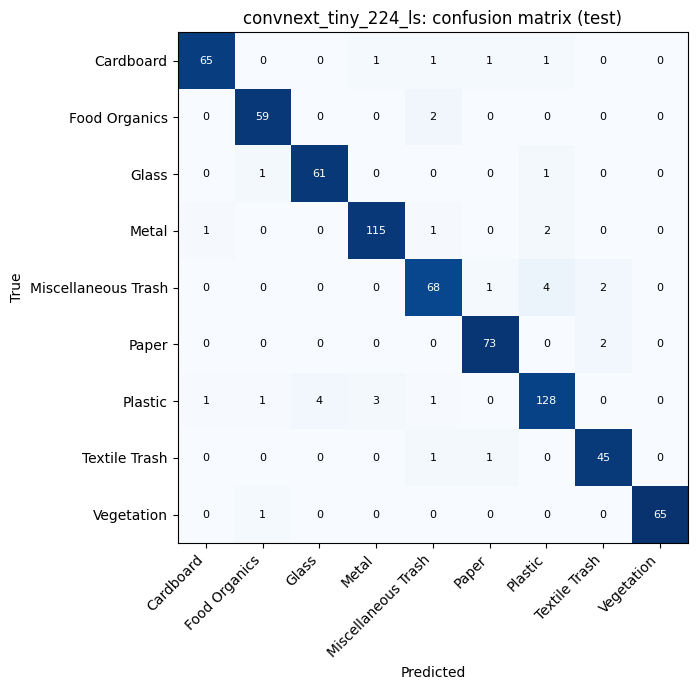


Saved to Drive.


In [ ]:
# ===== CELL 13: FINAL test-set evaluation (run once; no tuning after this) =====
import matplotlib.pyplot as plt
from scipy.stats import binomtest

yt = test_df["y"].values; K = len(classes)

def fast_metrics(y, pred):
    cm = np.bincount(y * K + pred, minlength=K * K).reshape(K, K)
    tp = np.diag(cm).astype(float)
    prec = tp / np.maximum(cm.sum(0), 1); rec = tp / np.maximum(cm.sum(1), 1)
    f1 = 2 * prec * rec / np.maximum(prec + rec, 1e-12)
    return tp.sum() / cm.sum(), f1.mean()

def boot_ci(y, pred, n=1000, seed=0):
    rng = np.random.default_rng(seed); N = len(y); fs = []
    for _ in range(n):
        i = rng.integers(0, N, N); fs.append(fast_metrics(y[i], pred[i])[1])
    return np.percentile(fs, [2.5, 97.5])

# ---- 1) test probabilities for every trained model (loaded from saved best checkpoints) ----
TP = {}; meta = {}
for f in sorted(glob.glob(f"{WORK}/results_*.json")):
    r = json.load(open(f)); tag = r["tag"]
    if not os.path.exists(f"{WORK}/ckpt_{tag}.pt"): continue
    meta[tag] = r
    tl = GPULoader(np.load(f"{WORK}/cache_test_384.npy"), yt, 64, False) if r["img_size"] == 384 else test_loader
    m = load_model(tag)
    TP[tag] = torch.softmax(evaluate(m, tl)["logits"], 1).numpy()
    del m; tl = None; gc.collect(); torch.cuda.empty_cache()
np.savez(f"{WORK}/test_probs.npz", **TP)

# ---- 2) ensembles (same members as in Cell 12) ----
ensA = ["convnext_tiny_224_ls", "convnext_tiny_224_ls_s1", "convnext_tiny_224_ls_s2"]
ensD = ensA + ["swin_tiny_patch4_window7_224_224", "vit_base_patch16_224_224"]
TP["ENSEMBLE A (3x ConvNeXt-T+LS)"] = np.mean([TP[t] for t in ensA], axis=0)
TP["ENSEMBLE D (A + Swin-T + ViT-B)"] = np.mean([TP[t] for t in ensD], axis=0)

# ---- 3) results table ----
rows = []
for tag, p in TP.items():
    pred = p.argmax(1); a, f = fast_metrics(yt, pred); lo, hi = boot_ci(yt, pred)
    r = meta.get(tag, {})
    rows.append({"run": tag, "params_M": round(r["params_M"], 1) if r else "-", "test_acc": round(a, 4), "test_F1": round(f, 4),
                 "F1_95%CI": f"[{lo:.3f}, {hi:.3f}]", "val_F1": round(r["val_f1"], 4) if r else "-"})
tab = pd.DataFrame(rows).sort_values("test_F1", ascending=False)
print(tab.to_string(index=False))
tab.to_csv(f"{WORK}/test_results.csv", index=False)

# ---- 4) main model in detail ----
MAIN = "convnext_tiny_224_ls"; p = TP[MAIN]; pred = p.argmax(1)
print(f"\n=== MAIN MODEL: {MAIN} (test set, n={len(yt)}) ===")
print(classification_report(yt, pred, target_names=classes, digits=3))
cm = confusion_matrix(yt, pred)
pairs = sorted([(cm[i, j], classes[i], classes[j]) for i in range(K) for j in range(K) if i != j and cm[i, j] > 0], reverse=True)[:6]
print("Top confusions (true -> predicted : count):"); [print(f"  {t:20s} -> {q:20s} : {c}") for c, t, q in pairs]

# McNemar vs Inception V3 (Paper 1's best architecture, same recipe/split)
ok_m = pred == yt; ok_i = TP["inception_v3_224"].argmax(1) == yt
b, c = int((ok_m & ~ok_i).sum()), int((~ok_m & ok_i).sum())
print(f"\nMcNemar vs Inception V3: main right/Inception wrong = {b}, main wrong/Inception right = {c}, p = {binomtest(b, b + c, 0.5).pvalue:.4f}")

# calibration + 'not sure' curve
conf = p.max(1); correct = ok_m
edges = np.linspace(0, 1, 16); ece = 0.0
for lo_, hi_ in zip(edges[:-1], edges[1:]):
    mk = (conf > lo_) & (conf <= hi_)
    if mk.any(): ece += mk.mean() * abs(correct[mk].mean() - conf[mk].mean())
print(f"\nExpected calibration error (15 bins): {ece:.3f}")
print("Confidence threshold -> coverage (answered) | accuracy on answered:")
for thr in (0.0, 0.5, 0.7, 0.8, 0.9, 0.95):
    mk = conf >= thr; print(f"  >= {thr:.2f}: {mk.mean()*100:5.1f}% answered | acc {correct[mk].mean():.4f}")

# confusion-matrix picture
fig, ax = plt.subplots(figsize=(8, 7)); cmn = cm / cm.sum(1, keepdims=True)
ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(K)); ax.set_yticks(range(K)); ax.set_xticklabels(classes, rotation=45, ha="right"); ax.set_yticklabels(classes)
for i in range(K):
    for j in range(K): ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", color="white" if cmn[i, j] > 0.5 else "black", fontsize=8)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"{MAIN}: confusion matrix (test)")
plt.tight_layout(); plt.savefig(f"{WORK}/confusion_main_test.png", dpi=120); plt.show()

DST = "/content/drive/MyDrive/EcoSort_ml"
for fn in ("test_probs.npz", "test_results.csv", "confusion_main_test.png"): shutil.copy2(f"{WORK}/{fn}", f"{DST}/{fn}")
print("\nSaved to Drive.")

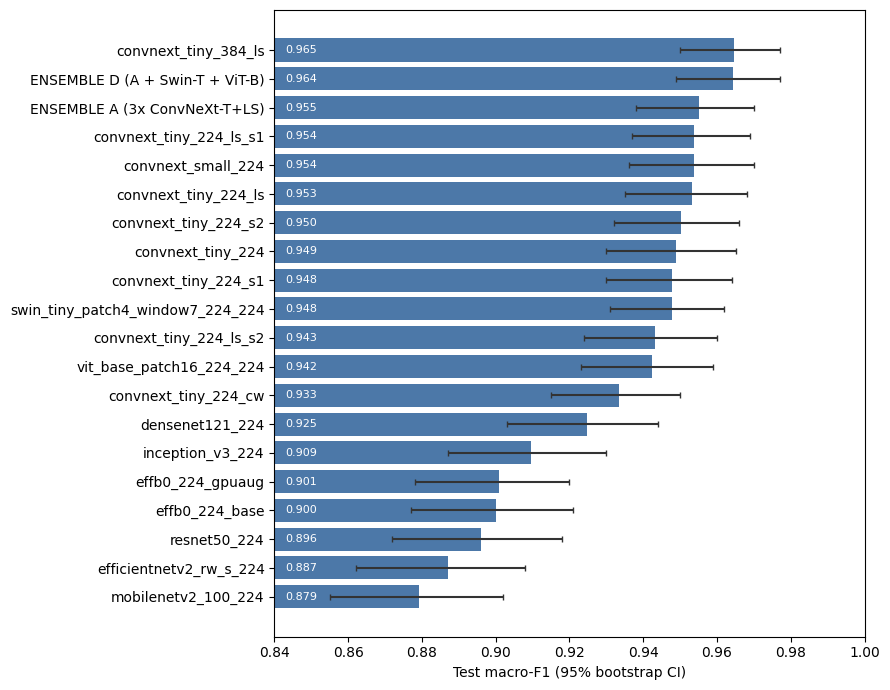

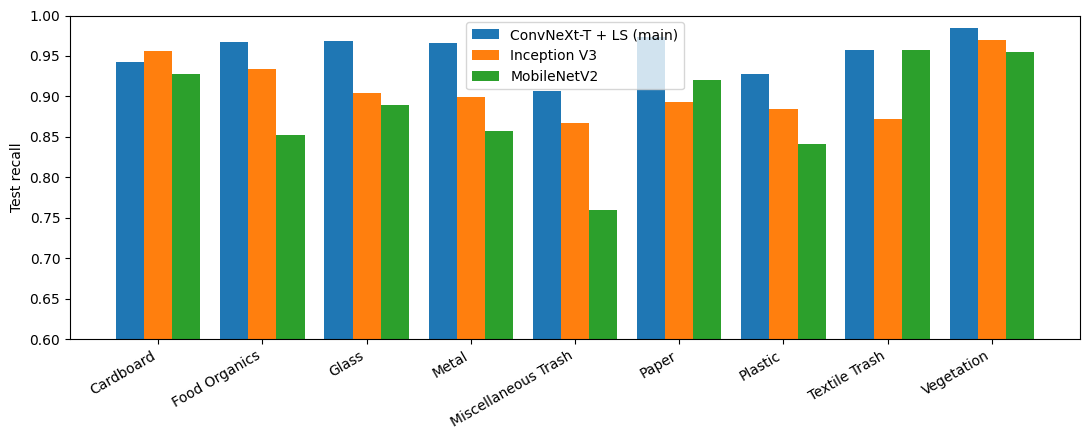

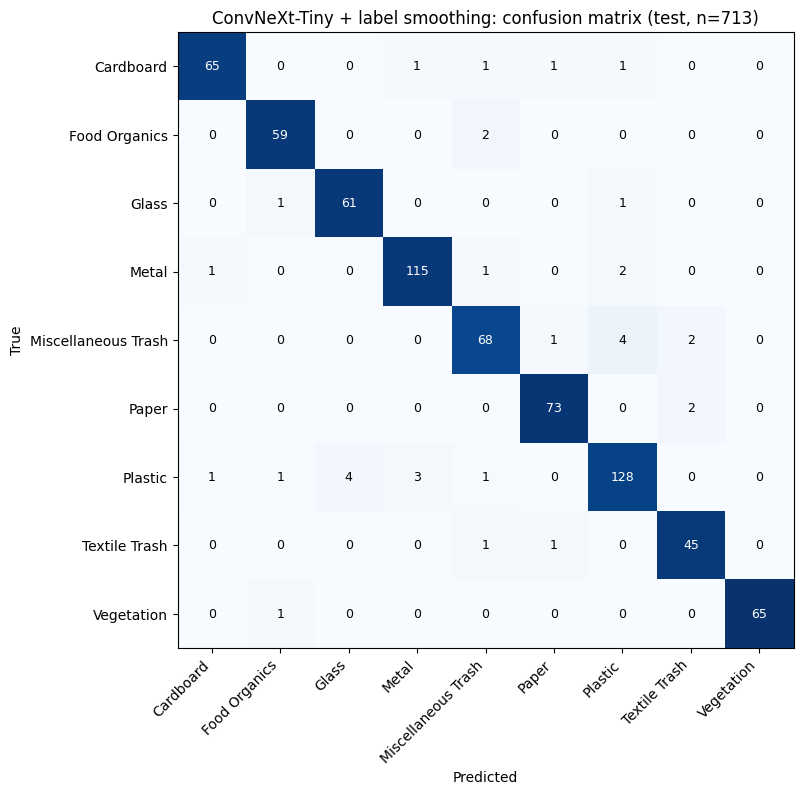

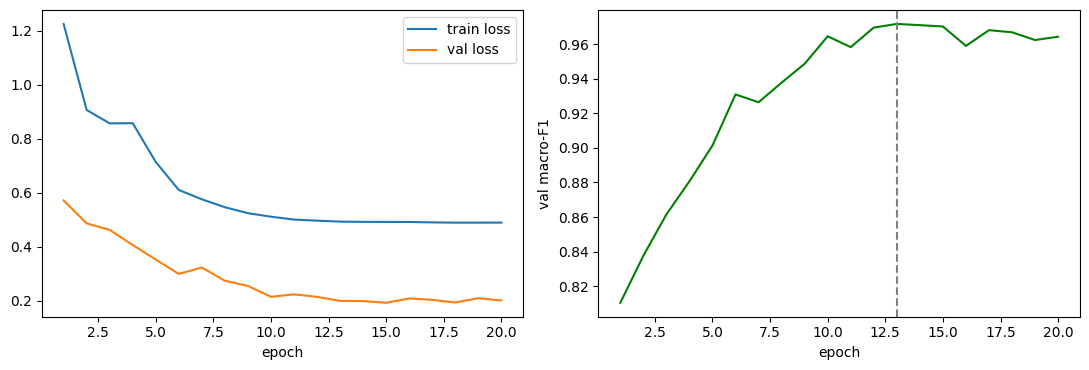

Temperature T = 0.616 (fit on val)  |  test ECE: 0.088 -> 0.026  |  test NLL: 0.233 -> 0.181
After scaling: threshold -> answered | accuracy on answered
  >= 0.00: 100.0% | acc 0.9523
  >= 0.50:  99.4% | acc 0.9535
  >= 0.70:  97.5% | acc 0.9640
  >= 0.80:  96.5% | acc 0.9709
  >= 0.90:  94.7% | acc 0.9763
  >= 0.95:  91.7% | acc 0.9817

                Source                        Model                         Split / setup            Accuracy     F1                                                                         Note
Paper 1 (Single 2023)                 Inception V3 own ~10% test, 524px, 80:20 train/val              89.19% 0.9025                                        Their own split; test set ~480 images
 Paper 2 (Obaid 2024)                 EfficientNet 50/20/30; dataset augmented to 19,008              96.31% 0.9643 Augmentation order unclear (possible leakage); results sections inconsistent
 Paper 3 (Kumar 2026)                    ResNet101                              

In [ ]:
# ===== CELL 14: Report figures + temperature scaling + paper-comparison table =====
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
FIG = f"{WORK}/figs"; os.makedirs(FIG, exist_ok=True)
MAIN = "convnext_tiny_224_ls"

# 1) test macro-F1 with 95% CI, all models
tab = pd.read_csv(f"{WORK}/test_results.csv").sort_values("test_F1")
ci = tab["F1_95%CI"].str.extract(r"\[([\d.]+), ([\d.]+)\]").astype(float)
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(tab["run"], tab["test_F1"], xerr=[tab["test_F1"] - ci[0], ci[1] - tab["test_F1"]], color="#4C78A8", ecolor="#333", capsize=2)
ax.set_xlim(0.84, 1.0); ax.set_xlabel("Test macro-F1 (95% bootstrap CI)")
for i, v in enumerate(tab["test_F1"]): ax.text(0.843, i, f"{v:.3f}", va="center", color="white", fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/1_test_f1_all_models.png", dpi=130); plt.show()

# 2) per-class recall: main vs Inception V3 vs MobileNetV2
names = {MAIN: "ConvNeXt-T + LS (main)", "inception_v3_224": "Inception V3", "mobilenetv2_100_224": "MobileNetV2"}
fig, ax = plt.subplots(figsize=(11, 4.5)); w = 0.27
for i, (t, lab) in enumerate(names.items()):
    ax.bar(np.arange(K) + (i - 1) * w, recall_score(yt, TP[t].argmax(1), average=None), w, label=lab)
ax.set_xticks(range(K)); ax.set_xticklabels(classes, rotation=30, ha="right"); ax.set_ylim(0.6, 1.0); ax.set_ylabel("Test recall"); ax.legend()
plt.tight_layout(); plt.savefig(f"{FIG}/2_per_class_recall.png", dpi=130); plt.show()

# 3) clean confusion matrix (main model, test)
cm = confusion_matrix(yt, TP[MAIN].argmax(1)); cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(9, 8)); ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(K)); ax.set_yticks(range(K)); ax.set_xticklabels(classes, rotation=45, ha="right"); ax.set_yticklabels(classes)
for i in range(K):
    for j in range(K): ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cmn[i, j] > 0.5 else "black", fontsize=9)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("ConvNeXt-Tiny + label smoothing: confusion matrix (test, n=713)")
plt.savefig(f"{FIG}/3_confusion_main.png", dpi=130, bbox_inches="tight"); plt.show()

# 4) training curves (main model)
h = meta[MAIN]["history"]; ep = [x["epoch"] for x in h]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(ep, [x["train_loss"] for x in h], label="train loss"); ax[0].plot(ep, [x["val_loss"] for x in h], label="val loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(ep, [x["val_f1"] for x in h], color="green"); ax[1].axvline(meta[MAIN]["best_epoch"], ls="--", color="gray"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("val macro-F1")
plt.tight_layout(); plt.savefig(f"{FIG}/4_training_curves.png", dpi=130); plt.show()

# 5) temperature scaling: fit T on VAL, evaluate on TEST (accuracy is unchanged)
Pv = np.load(f"{WORK}/val_probs.npz")["cnx_t_ls"]; Pt = TP[MAIN]
def nll(T, P, y): q = np.exp(np.log(P + 1e-12) / T); q /= q.sum(1, keepdims=True); return -np.log(q[np.arange(len(y)), y] + 1e-12).mean()
T = minimize_scalar(lambda t: nll(t, Pv, yv), bounds=(0.3, 3.0), method="bounded").x
def scale(P, T): q = np.exp(np.log(P + 1e-12) / T); return q / q.sum(1, keepdims=True)
def ece_of(P, y, nb=15):
    conf, ok = P.max(1), P.argmax(1) == y; e = np.linspace(0, 1, nb + 1); s = 0.0
    for a, b in zip(e[:-1], e[1:]):
        mk = (conf > a) & (conf <= b)
        if mk.any(): s += mk.mean() * abs(ok[mk].mean() - conf[mk].mean())
    return s
Ps = scale(Pt, T)
print(f"Temperature T = {T:.3f} (fit on val)  |  test ECE: {ece_of(Pt, yt):.3f} -> {ece_of(Ps, yt):.3f}  |  test NLL: {nll(1.0, Pt, yt):.3f} -> {nll(T, Pt, yt):.3f}")
conf, ok = Ps.max(1), Ps.argmax(1) == yt
print("After scaling: threshold -> answered | accuracy on answered")
for thr in (0.0, 0.5, 0.7, 0.8, 0.9, 0.95): mk = conf >= thr; print(f"  >= {thr:.2f}: {mk.mean()*100:5.1f}% | acc {ok[mk].mean():.4f}")

# 6) paper comparison table (as reported, with caveats)
t = tab.set_index("run")
comp = pd.DataFrame([
 ["Paper 1 (Single 2023)", "Inception V3", "own ~10% test, 524px, 80:20 train/val", "89.19%", "0.9025", "Their own split; test set ~480 images"],
 ["Paper 2 (Obaid 2024)", "EfficientNet", "50/20/30; dataset augmented to 19,008", "96.31%", "0.9643", "Augmentation order unclear (possible leakage); results sections inconsistent"],
 ["Paper 3 (Kumar 2026)", "ResNet101", "70/15/15", "98.86% (VALIDATION)", "0.99", "Validation, not test; full methods not verified by us"],
 ["Ours (main)", "ConvNeXt-T + label smoothing", "70/15/15 stratified, 224px", f"{t.loc[MAIN,'test_acc']*100:.2f}% (test)", f"{t.loc[MAIN,'test_F1']:.4f}", f"95% CI F1 {t.loc[MAIN,'F1_95%CI']}; val acc {meta[MAIN]['val_acc']*100:.2f}%"],
 ["Ours (Paper-1 arch)", "Inception V3, our recipe", "70/15/15 stratified, 224px", f"{t.loc['inception_v3_224','test_acc']*100:.2f}% (test)", f"{t.loc['inception_v3_224','test_F1']:.4f}", "Same split/recipe as main"],
], columns=["Source", "Model", "Split / setup", "Accuracy", "F1", "Note"])
comp.to_csv(f"{WORK}/paper_comparison.csv", index=False); print("\n", comp.to_string(index=False))

DST = "/content/drive/MyDrive/EcoSort_ml"
shutil.copytree(FIG, f"{DST}/figs", dirs_exist_ok=True); shutil.copy2(f"{WORK}/paper_comparison.csv", f"{DST}/paper_comparison.csv")
print("\nSaved figures + table to Drive.")

In [ ]:
# ===== CELL 15: ONNX export + CPU size / speed / parity check =====
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "onnx", "onnxruntime", "onnxscript"], check=False)
import onnx, onnxruntime as ort
MAIN, T = "convnext_tiny_224_ls", 0.616
ONNX_PATH = f"{WORK}/ecosort_convnext_tiny.onnx"

# ---- 1) export ----
m = load_model(MAIN).cpu().to(memory_format=torch.contiguous_format).eval()
dummy = torch.randn(1, 3, 224, 224)
def export(**kw):
    torch.onnx.export(m, dummy, ONNX_PATH, input_names=["image"], output_names=["logits"],
                      dynamic_axes={"image": {0: "batch"}, "logits": {0: "batch"}}, **kw)
try:
    export(opset_version=17, dynamo=False)
except Exception as e:
    print("legacy exporter failed, trying the new one:", repr(e)[:150]); export(dynamo=True)
onnx.checker.check_model(ONNX_PATH)
print(f"Exported OK: {os.path.getsize(ONNX_PATH)/1e6:.1f} MB")
del m

# ---- 2) int8 compressed version (optional; may be slower on some CPUs) ----
INT8_PATH = f"{WORK}/ecosort_convnext_tiny_int8.onnx"
try:
    from onnxruntime.quantization import quantize_dynamic, QuantType
    quantize_dynamic(ONNX_PATH, INT8_PATH, weight_type=QuantType.QUInt8)
except Exception as e:
    INT8_PATH = None; print("int8 quantization skipped:", repr(e)[:200])

# ---- 3) helpers ----
mean_ = np.array(MEAN, np.float32).reshape(1, 3, 1, 1); std_ = np.array(STD, np.float32).reshape(1, 3, 1, 1)
def prep(x_uint8_nhwc): return (((x_uint8_nhwc.astype(np.float32) / 255).transpose(0, 3, 1, 2) - mean_) / std_).astype(np.float32)
def softmax_np(z): z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)
def session(path): return ort.InferenceSession(path, ort.SessionOptions(), providers=["CPUExecutionProvider"])

def bench(sess, n=60):
    x = prep(X_test[:1])
    for _ in range(5): sess.run(None, {"image": x})
    ts = []
    for _ in range(n):
        t0 = time.perf_counter(); sess.run(None, {"image": x}); ts.append((time.perf_counter() - t0) * 1000)
    return np.median(ts), np.percentile(ts, 95)

paths = test_df["path"].tolist()[:30]
def end_to_end(sess):                      # JPEG decode + resize + normalise + predict + softmax
    ts = []
    for p in paths:
        t0 = time.perf_counter()
        im = Image.open(os.path.join(DATA_DIR, p)).convert("RGB").resize((224, 224), Image.BICUBIC)
        softmax_np(sess.run(None, {"image": prep(np.asarray(im)[None])})[0] / T)
        ts.append((time.perf_counter() - t0) * 1000)
    return np.median(ts[3:])

def run_all(sess, X, bs=32):
    return np.concatenate([sess.run(None, {"image": prep(X[i:i + bs])})[0] for i in range(0, len(X), bs)])

# ---- 4) evaluate each exported file ----
print(f"\nCPU cores available here: {os.cpu_count()} (your hosting server will differ)\n")
ref_pred = TP[MAIN].argmax(1)
for name, path in [("fp32", ONNX_PATH), ("int8", INT8_PATH)]:
    if not path: continue
    sess = session(path)
    med, p95 = bench(sess); e2e = end_to_end(sess)
    t0 = time.time(); lg = run_all(sess, X_test); dt = time.time() - t0
    pr = softmax_np(lg / T); pred = pr.argmax(1); acc, f1 = fast_metrics(yt, pred)
    print(f"[{name}] size {os.path.getsize(path)/1e6:6.1f} MB | model only: median {med:5.0f} ms, p95 {p95:5.0f} ms | "
          f"full pipeline: median {e2e:5.0f} ms")
    print(f"       test acc {acc:.4f} F1 {f1:.4f} | same prediction as PyTorch on {np.mean(pred == ref_pred)*100:.1f}% of 713 images"
          f" | max prob diff vs PyTorch {np.abs(softmax_np(lg) - TP[MAIN]).max():.3f} | whole test set in {dt:.0f}s")
try:
    import psutil; print(f"\nProcess memory now: {psutil.Process().memory_info().rss/1e9:.1f} GB (includes the Colab session, so an upper bound)")
except Exception: pass

# ---- 5) config for the backend + backup ----
cfg = {"model": "convnext_tiny (timm), label smoothing 0.1, trained on RealWaste", "onnx_file": "ecosort_convnext_tiny.onnx",
       "input": "float32 [batch,3,224,224]", "preprocess": "RGB image -> resize WHOLE image to 224x224 with PIL BICUBIC (no crop) -> /255 -> (x-mean)/std",
       "mean": MEAN, "std": STD, "classes": classes, "temperature": T, "output": "logits; probs = softmax(logits / temperature)",
       "not_sure_threshold": 0.80}
json.dump(cfg, open(f"{WORK}/model_config.json", "w"), indent=2)
DST = "/content/drive/MyDrive/EcoSort_ml"
for fn in ["ecosort_convnext_tiny.onnx", "model_config.json"] + (["ecosort_convnext_tiny_int8.onnx"] if INT8_PATH else []):
    shutil.copy2(f"{WORK}/{fn}", f"{DST}/{fn}")
print("Saved ONNX file(s) + model_config.json to Drive.")

/tmp/ipykernel_664/2357580761.py:11: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(m, dummy, ONNX_PATH, input_names=["image"], output_names=["logits"],


Exported OK: 111.4 MB



CPU cores available here: 2 (your hosting server will differ)

[fp32] size  111.4 MB | model only: median   107 ms, p95   127 ms | full pipeline: median   119 ms
       test acc 0.9523 F1 0.9532 | same prediction as PyTorch on 100.0% of 713 images | max prob diff vs PyTorch 0.004 | whole test set in 89s
[int8] size   28.2 MB | model only: median   201 ms, p95   219 ms | full pipeline: median   208 ms
       test acc 0.9537 F1 0.9550 | same prediction as PyTorch on 99.3% of 713 images | max prob diff vs PyTorch 0.182 | whole test set in 151s

Process memory now: 7.4 GB (includes the Colab session, so an upper bound)
Saved ONNX file(s) + model_config.json to Drive.
